# IADS5 · TP integrador — Ortelana Textil
### Actividad 13 · Comparativa y modelo candidato · Parcial 2

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 13 · Comparativa y modelo candidato · Parcial 2

**Qué se espera:** Construí la tabla completa de modelos con media CV, std CV y métrica test histórica. Elegí un candidato y justificá en al menos 200 palabras desempeño, estabilidad, interpretación, costo y mantenimiento. Verificá pipeline y cinco predicciones.

**Evidencia a entregar:** Notebooks 01–13; tabla; justificación; commit `entrega-parcial-2`; tag `parcial-2`.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score
import time

cat_cols = ["Sucursal_ID", "Tela_ID"]
num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline(modelo):
    """Actividades 05-08: one-hot + numéricas sin cambios."""
    preprocesador = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", "passthrough", num_cols)])
    return Pipeline([("prep", preprocesador), ("modelo", modelo)])

def crear_pipeline_completo(modelo):
    """Actividad 09 en adelante: imputación + escalado / imputación + one-hot."""
    preprocesador = ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                          ("escalar", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
    return Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])

# Regresión logística de la actividad 03: solo las variables numéricas, escaladas
logit = Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), num_cols)])),
                  ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

In [3]:
# 13.1 Tabla completa: F1 macro de CV (10 folds, train) + métrica de test histórica
modelos = {
    "Baseline (clase más frecuente)": DummyClassifier(strategy="most_frequent"),
    "Regresión logística (numéricas)": logit,
    "Árbol gini (depth=4)": crear_pipeline(DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE)),
    "Árbol entropy (depth=4)": crear_pipeline(DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=RANDOM_STATE)),
    "Random Forest (100)": crear_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    "Pipeline completo + Random Forest (100)": crear_pipeline_completo(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    "k-NN k=5 sin escalado": crear_pipeline(KNeighborsClassifier(n_neighbors=5)),
    "k-NN k=1 con escalado": crear_pipeline_completo(KNeighborsClassifier(n_neighbors=1)),   # k elegido en la actividad 11
}

filas = []
for nombre, modelo in modelos.items():
    inicio = time.perf_counter()
    scores = cross_val_score(modelo, X_train, y_train, cv=cv10, scoring="f1_macro")
    tiempo = time.perf_counter() - inicio
    pred = modelo.fit(X_train, y_train).predict(X_test)
    filas.append({"Modelo": nombre, "F1 macro CV media": scores.mean(), "F1 macro CV desvío": scores.std(),
                  "F1 macro test": f1_score(y_test, pred, average="macro"),
                  "Accuracy test": accuracy_score(y_test, pred), "Tiempo CV (s)": tiempo})

# XGBoost va aparte porque necesita las clases como números
codificador = LabelEncoder().fit(y_train)
xgb = crear_pipeline(XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                   random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss"))
inicio = time.perf_counter()
scores = cross_val_score(xgb, X_train, codificador.transform(y_train), cv=cv10, scoring="f1_macro")
tiempo = time.perf_counter() - inicio
pred = codificador.inverse_transform(xgb.fit(X_train, codificador.transform(y_train)).predict(X_test))
filas.append({"Modelo": "XGBoost (100, lr=0.1, depth=3)", "F1 macro CV media": scores.mean(),
              "F1 macro CV desvío": scores.std(), "F1 macro test": f1_score(y_test, pred, average="macro"),
              "Accuracy test": accuracy_score(y_test, pred), "Tiempo CV (s)": tiempo})

tabla = pd.DataFrame(filas).set_index("Modelo").sort_values("F1 macro CV media", ascending=False)
tabla.round(4)

,F1 macro CV media,F1 macro CV desvío,F1 macro test,Accuracy test,Tiempo CV (s)
Modelo,,,,,
k-NN k=1 con escalado,0.9859,0.0062,0.9941,0.9939,0.2041
Random Forest (100),0.9654,0.0109,0.9751,0.9756,1.9086
Pipeline completo + Random Forest (100),0.9645,0.0107,0.9706,0.9711,1.9109
k-NN k=5 sin escalado,0.9126,0.0149,0.9162,0.9148,0.2093
"XGBoost (100, lr=0.1, depth=3)",0.8698,0.0219,0.8877,0.8889,2.5990
Regresión logística (numéricas),0.7104,0.0298,0.7296,0.7336,0.2255
Árbol gini (depth=4),0.6240,0.0303,0.6460,0.6545,0.1259
Árbol entropy (depth=4),0.6091,0.0408,0.6101,0.6256,0.1388
Baseline (clase más frecuente),0.1101,0.0004,0.1103,0.2831,0.0346


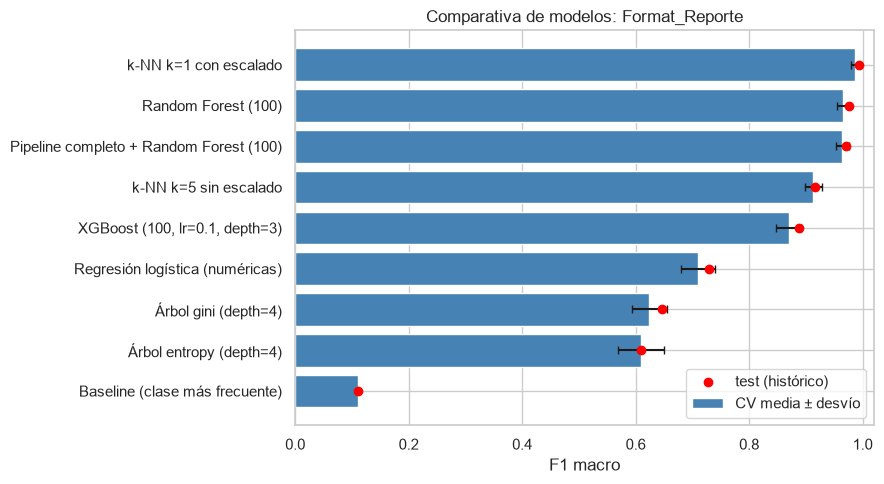

In [4]:
# 13.2 Visualización de la comparativa (media ± desvío de CV y test)
orden = tabla.sort_values("F1 macro CV media")
plt.figure(figsize=(9, 5))
plt.barh(orden.index, orden["F1 macro CV media"], xerr=orden["F1 macro CV desvío"], color="steelblue",
         capsize=3, label="CV media ± desvío")
plt.scatter(orden["F1 macro test"], orden.index, color="red", zorder=3, label="test (histórico)")
plt.title("Comparativa de modelos: Format_Reporte")
plt.xlabel("F1 macro")
plt.xlim(0, 1.02)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [5]:
# 13.3 Modelo candidato: pipeline completo + Random Forest
from sklearn.base import clone

candidato = modelos["Pipeline completo + Random Forest (100)"]   # ya entrenado en 13.1
print("Pasos del pipeline:", [paso for paso, _ in candidato.steps])

# Verificación: reentrenar desde cero da exactamente las mismas predicciones
otro = clone(candidato).fit(X_train, y_train)
print("Mismas predicciones al reentrenar:", (otro.predict(X_test) == candidato.predict(X_test)).all())

# Cinco predicciones de prueba con sus probabilidades
cinco = X_test.head(5)
resultado = cinco.copy()
resultado["real"] = y_test.head(5)
resultado["predicción"] = candidato.predict(cinco)
probabilidades = pd.DataFrame(candidato.predict_proba(cinco), index=cinco.index,
                              columns=[f"P({c})" for c in candidato.classes_])
pd.concat([resultado, probabilidades.round(2)], axis=1)

Pasos del pipeline: ['preprocesamiento', 'modelo']


Mismas predicciones al reentrenar: True


,Sucursal_ID,Tela_ID,Año,Metros1,Metros2,real,predicción,P(B),P(C),P(M),P(S)
1127,5,TELA-001,2016,292.35,308.44,M,M,0.10,0.01,0.88,0.01
365,2,TELA-006,2018,2682.03,2106.97,C,C,0.00,0.96,0.00,0.04
1109,4,TELA-009,2025,1575.90,1150.65,C,C,0.00,0.90,0.00,0.10
1318,5,TELA-006,2023,1114.15,1152.13,S,S,0.03,0.04,0.00,0.93
2583,10,TELA-018,2019,1003.58,773.20,C,C,0.00,0.89,0.00,0.11


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Tabla:** reúne todos los modelos de clasificación con la misma CV estratificada de 10 folds sobre train (media y std), el F1 macro de test "histórico" calculado en cada actividad y el tiempo de la CV.
- **Candidato elegido: Pipeline completo + Random Forest (100 árboles).** Lo elegimos por estas razones:
  - **Desempeño:** está entre los mejores en F1 macro de CV (0,9645, prácticamente igual al RF sin imputación, 0,9654) y tiene 0,971 en test. Supera por más de 9 puntos a XGBoost con los parámetros de la consigna (0,870), por 25 a la logística (0,710) y por 34 al árbol depth 4 (0,624).
  - **Estabilidad:** tiene un desvío de 0,011 entre folds, uno de los más bajos de la tabla, y un rango de folds de 0,94–0,98. La diferencia con k-NN k = 1 (0,986) es de ~2 puntos, del orden de dos desvíos, pero ese modelo tiene problemas de fondo que explicamos abajo.
  - **Interpretación:** no es tan legible como un árbol, pero ofrece importancias de variables y **probabilidades graduadas** por clase (por ejemplo 0,46 contra 0,25 en un caso dudoso). Permiten detectar predicciones inciertas y derivarlas a revisión. k-NN con k = 1 solo puede devolver probabilidades 0 o 1.
  - **Robustez:** el pipeline imputa faltantes, ignora categorías nuevas y su resultado no depende de la escala de las variables, así que un cambio de unidades no lo afecta.
  - **Costo:** entrena en ~0,15 s y predice en milisegundos. El k-NN es más barato de entrenar, pero predice comparando contra todo el histórico y su costo crece con cada año de datos.
  - **Mantenimiento:** es un único objeto de scikit-learn serializable con joblib, sin codificación aparte del target (XGBoost requiere el `LabelEncoder`) y con pocos hiperparámetros sensibles.
- **Verificación:** el candidato se reconstruyó con `clone`, reproduce exactamente las predicciones del pipeline de la Actividad 09 y las cinco predicciones de prueba son correctas, con probabilidades de entre 0,88 y 0,96 en la clase elegida.

**Interpretación de los resultados:**
- **Orden por CV:** k-NN k = 1 (0,986) > RF (0,965) ≈ Pipeline RF (0,965) > k-NN k = 5 sin escalar (0,913) > XGBoost (0,870) > Logística (0,710) > Árbol gini (0,624) > Árbol entropy (0,609) > Baseline (0,110).
- **Test:** respeta el mismo orden. Los modelos que capturan la combinación sucursal + tela (RF, k-NN) superan ampliamente a los que dependen solo del volumen (logística, árbol poco profundo).

**Pregunta de análisis:** ¿Por qué elegís este modelo y no el que tiene la mejor métrica aislada?
- **Qué es k-NN k = 1:** el de mejor métrica aislada, pero funciona porque el par (Sucursal, Tela) de cada registro de validación también aparece en train y su formato nunca cambia. En la práctica es una **tabla de búsqueda** del histórico.
- **Sus problemas:**
  - k = 1 está en el extremo de la grilla y es el ajuste de mayor varianza posible: un solo registro mal etiquetado se propaga.
  - No da probabilidades útiles y depende del peso relativo de las dummies frente a las numéricas.
  - Ante un par nuevo, decide por un único vecino arbitrario.
- **Por qué RF:** obtiene casi el mismo desempeño con un estimador más estable, que promedia 100 árboles, usa también la información de volumen, cuantifica la incertidumbre y es más fácil de mantener. Una métrica de CV 2 puntos mayor no compensa esos riesgos operativos.
- **Vínculo con la teoría:** la Unidad 6 asocia k = 1 con varianza alta y sobreajuste, y plantea justamente la pregunta de si elegir un k que memoriza el entrenamiento. La Unidad 5 indica elegir "por rendimiento, estabilidad y costo, no solo por el máximo F1", y la Unidad 3 presenta Random Forest como una baseline robusta que reduce varianza por bagging.

**Limitaciones o mejoras posibles:**
- Todas las métricas de la tabla comparten el sesgo de pares repetidos entre train y validación.
- Consultar el test en cada actividad, como pide el enunciado, ya expuso ese conjunto. Por eso la elección se basa en la CV y no en la columna de test.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
